Part A:Python Programming Code


**1.Import Necessary Libraries**

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

import tensorflow as tf
from tensorflow.keras import layers, models
from tensorflow.keras.datasets import fashion_mnist
from tensorflow.keras.utils import to_categorical
from tensorflow.keras.callbacks import EarlyStopping, ReduceLROnPlateau
from tensorflow.keras.preprocessing.image import ImageDataGenerator

from sklearn.metrics import confusion_matrix, classification_report
from sklearn.model_selection import train_test_split

Explaination:

*   Library:numpy
    It used for handing numerical operations and array manipulation.   
    
*   Library:matpplotlib
    It used to import the pyplot module of the matplotlib library for plotting.

*   Library:seaborn
    It used to plot the confusion matrix in a more clearer,visually appealing way.

*   Library:tensorflow
    It is the core framwork of this project and we used it to create,train and evaluate the CNN model.


*   Library:keras
   1. layers, models:
    It used to construct the CNN architecture such as convolutional layers,pooling layers and fully connected layers.

   2. fashion_mnist:
    It used to load our target  Fashion-MNIST dataset.

   3. to_categorical:
    It can convert the class labels into one-hot encoded vectors.

   4. EarlyStopping:
    It can stop the training process when the validation loss is not increase.

   5. ReduceLROnPlateau:
    It can help up to better convergence by reducing the learning rate when the model's performance is not improve.

   6. ImageDataGenerator:
    It can used to improve the generailze ability of the model.

*   Library:scikit-learn
   1. confusion_matrix:
    It used to calculate confusion matrix,and can analysied the classificated performance.

   2. classification_report:
    It used to generate Precision,Recall and F1-score.

   3. train_test_split:
    It used to divide the training datat into training dataset and vaildation dataset.

**2. Load and Prepare the Image Data**



In [ ]:
#Loads the Fashion-MNIST dataset and splits it into training and test sets.
(X_train_full, y_train_full), (X_test, y_test) = fashion_mnist.load_data()

#Normalizes the pixel values to the range [0, 1]
X_train_full = X_train_full / 255.0
X_test = X_test / 255.0

#Reshapes the images
X_train_full = X_train_full.reshape(-1, 28, 28, 1)
X_test = X_test.reshape(-1, 28, 28, 1)

#plits the original training data into training and validation sets.
X_train, X_val, y_train, y_val = train_test_split(
    X_train_full, y_train_full, test_size=0.2, random_state=42
)

#convert class labels into one-hot encoded vectors
num_classes = 10
y_train_cat = to_categorical(y_train, num_classes)
y_val_cat = to_categorical(y_val, num_classes)
y_test_cat = to_categorical(y_test, num_classes)


#data augmentation (only for training set)
datagen = ImageDataGenerator(
    rotation_range=10,
    zoom_range=0.1,
    width_shift_range=0.1,
    height_shift_range=0.1
)
datagen.fit(X_train)

print("Training set:", X_train.shape, y_train_cat.shape)
print("Validation set:", X_val.shape, y_val_cat.shape)
print("Test set:", X_test.shape, y_test_cat.shape)


29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
Training set: (48000, 28, 28, 1) (48000, 10)
Validation set: (12000, 28, 28, 1) (12000, 10)
Test set: (10000, 28, 28, 1) (10000, 10)


Explaination:

In this part,the Fashion-MNIST dataset is loaed by using Keras and used for image classification.

This dataset is first divided into a training set and a test set,each image is set as 28*28 grayscale and represent as a clothes.
Before training the model, all images pixel value are divided by 255 to scale their value and let their value into the range[0,1].This normalization step helps improve numerical stability,ensure a more efficient converge and prevent large fradients in the training process.Also,we reshape image data to add a channel dimension,providing clear channel information for convolutional neural networks.

Then,the original training set is divided into a training set and a validation set.The training set is used to learn the model's parametres.The validation set is used to monitor the performance of the model to reduce overfitting.
Finally,all class labels sre converted into one-hot encoded vectors so they can be used with the softmax output layer.Meanwhile,data augmentation techniques also applied to improve their generalization ability in the training set.

**3.Build CNN Model**

In [ ]:
#create a sequential model
model = models.Sequential([

#3 convolution layer, batchnorm and maxpooling
    layers.Conv2D(32, (3,3), activation='relu', input_shape=(28,28,1)),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(64, (3,3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

    layers.Conv2D(128, (3,3), activation='relu'),
    layers.BatchNormalization(),
    layers.MaxPooling2D((2,2)),

#flatten the features and pass it to fully connected layer
    layers.Flatten(),
#dense layer
    layers.Dense(128, activation='relu'),
#Randomly drop some neurons to avoid overfitting
    layers.Dropout(0.5),
#show the probabilities
    layers.Dense(10, activation='softmax')
])

model.summary()


/usr/local/lib/python3.13/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 26, 26, 32)     │           320 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 26, 26, 32)     │           128 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 13, 13, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 11, 11, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 11, 11, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 5, 5, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 3, 3, 128)      │        73,856 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 3, 3, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 1, 1, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 128)            │        16,512 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dropout (Dropout)               │ (None, 128)            │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 10)             │         1,290 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 111,370 (435.04 KB)

 Trainable params: 110,922 (433.29 KB)

 Non-trainable params: 448 (1.75 KB)

Explaination:

In this part,the keras sequential API is used to build this CNN model.This model has 3 convolutional layers and each convolutional layer is followed by batch normalization and max pooling to extract image features and reduce the size of feature maps.

The *ReLU activatiion function*  is also applied in the convolutional layer and hidden fully connected layer,provideing nonlinear ability to identify complex image features.
In the output layer,*softmax* is also applied to convert all the final output into  numbers and each number represent the probability of the corresponidng category.Before it passed to output layer, the convolutional layer extract image's 3D features(height x Width x Number of Channels).Then,the flatten layer converts these 3D feature into 1D vector for the fully connected layers.At the same time,the droupout layer help prevent overfitting.Finally, *model.summary()* is used to see the output shapes and number of parametres of each layers.

**4.Compile CNN Model**

In [ ]:
model.compile(
    optimizer='adam', # Adam optimizer for efficient gradient descent
    loss='categorical_crossentropy',# Loss function for multi-class classification
    metrics=['accuracy'] # Track accuracy
)

Explaination:

In the compile part,the *adam* optimizer is used to fast training convergence and automatically adjust the learning rate of different parametres, *categorical_crossentropy* loss for muti-class classifictaion,*metrics* to monitor the accuracy on training and validation sets.


**Train CNN Model**

In [ ]:
#early stop to prevent overfitting
early_stop = EarlyStopping(monitor='val_loss', patience=5, restore_best_weights=True)
# reduce learning rate if val_loss plateaus for 3 epochs
reduce_lr = ReduceLROnPlateau(monitor='val_loss', factor=0.5, patience=3, min_lr=1e-5)


history = model.fit(
    datagen.flow(X_train, y_train_cat, batch_size=128),
    epochs=30,# number of epochs
    validation_data=(X_val, y_val_cat),
    callbacks=[early_stop, reduce_lr]
)


Epoch 1/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 90s 232ms/step - accuracy: 0.7042 - loss: 0.8278 - val_accuracy: 0.3722 - val_loss: 1.5097 - learning_rate: 0.0010
Epoch 2/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 87s 232ms/step - accuracy: 0.7884 - loss: 0.5802 - val_accuracy: 0.8305 - val_loss: 0.4588 - learning_rate: 0.0010
Epoch 3/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 143s 236ms/step - accuracy: 0.8135 - loss: 0.5179 - val_accuracy: 0.8420 - val_loss: 0.4264 - learning_rate: 0.0010
Epoch 4/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 92s 245ms/step - accuracy: 0.8275 - loss: 0.4811 - val_accuracy: 0.8265 - val_loss: 0.4691 - learning_rate: 0.0010
Epoch 5/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 85s 226ms/step - accuracy: 0.8324 - loss: 0.4614 - val_accuracy: 0.8358 - val_loss: 0.4434 - learning_rate: 0.0010
Epoch 6/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 83s 221ms/step - accuracy: 0.8408 - loss: 0.4416 - val_accuracy: 0.8655 - val_loss: 0.3732 - learning_rate: 0.0010
Epoch 7/30
375/375 ━━━━━━━━━━━━━━━━━━━━ 83s 221ms/step - accuracy: 0.

Explaination:

In the training part,callback function like *EarlyStopping* is applied when the validation loss does not improve in several rounds,while *ReduceLROnPlateau* is used to lower the learning rate when training becomes slower.In addition,*datagen.flow* is used to enhances the training data in real time and improve its generalization ability.The model totally train 48000 images, batch size is 128, trained for 30 epochs.

**Plot the training and validation accuracy and loss over epochs**

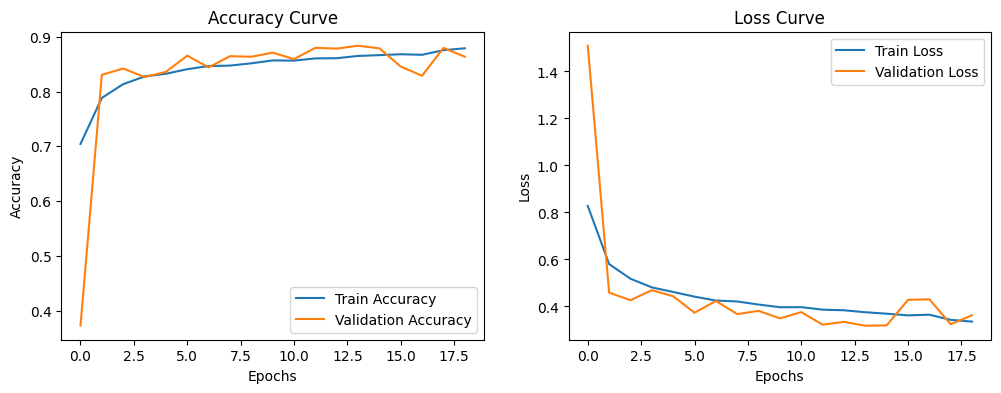

In [ ]:
plt.figure(figsize=(12,4))

#plot accuracy
plt.subplot(1,2,1)
plt.plot(history.history['accuracy'], label='Train Accuracy')
plt.plot(history.history['val_accuracy'], label='Validation Accuracy')
plt.xlabel('Epochs')
plt.ylabel('Accuracy')
plt.legend()
plt.title('Accuracy Curve')

#plot loss
plt.subplot(1,2,2)
plt.plot(history.history['loss'], label='Train Loss')
plt.plot(history.history['val_loss'], label='Validation Loss')
plt.xlabel('Epochs')
plt.ylabel('Loss')
plt.legend()
plt.title('Loss Curve')

plt.show()


Explaination:

In this part,the *plt.figure(figsize=(12,4))* is used to create  enough space for two plots,*plt.subplot(1,2,1)* and *plt.subplot(1,2,2)* split the figure into two subplots.In the first subplot,the model use the values stored in *history.history* and plot the training accuracy and validation accuracy.These curbes shows the training and validation accuracy of each epochs, while the x-axis represents the number of epochs and the y-axis represents accuracy.In the second subplot,it shows the training and validation loss. These loss curves how the model learns during training.Also,labels, legends, and titles are added in the plot.

**5.Evaluate the model**

In [ ]:
#evaluate the accuracy on the test set
test_loss, test_accuracy = model.evaluate(X_test, y_test_cat)
print("Test Accuracy:", test_accuracy)

y_prob = model.predict(X_test)
# convert probabilities to class labels
y_pred = np.argmax(y_prob, axis=1)

#print precision, recall, f1-score
print(classification_report(y_test, y_pred))


313/313 ━━━━━━━━━━━━━━━━━━━━ 6s 20ms/step - accuracy: 0.8770 - loss: 0.3386
Test Accuracy: 0.8769999742507935
313/313 ━━━━━━━━━━━━━━━━━━━━ 5s 14ms/step
              precision    recall  f1-score   support

           0       0.82      0.85      0.83      1000
           1       0.99      0.97      0.98      1000
           2       0.86      0.76      0.81      1000
           3       0.89      0.85      0.87      1000
           4       0.76      0.86      0.81      1000
           5       0.95      0.98      0.97      1000
           6       0.63      0.64      0.63      1000
           7       0.96      0.93      0.94      1000
           8       0.97      0.97      0.97      1000
           9       0.96      0.96      0.96      1000

    accuracy                           0.88     10000
   macro avg       0.88      0.88      0.88     10000
weighted avg       0.88      0.88      0.88     10000



Explaination:

In this part,the model is evaluated using accuracy as the main performance metric on the test set. The *model.evaluate()* function is used to calculate the test loss and test accuracy.It reflects the overall classification performance on unseen data.

The *model.predict()* function is used to generate prediction probabilities for each test image. And after the predicted class labels are  distributed, *argmax.* function is applied to the  highest probability class as the final predicted label.

Finally, *classification_report()* is used to show precision, recall and F1-score for each class, providing a detailed performance evaluation of each classes. From the repost,classes 1,3,5, 7, 8 and 9 have relatively high precision, recall and F1 score.It show these five classes are classified very accurate.Meanwhile class 6 has a relatively low result compare to other classed,it shows that images from class 6  are easily to be identified as the wrong category.

**Confusion Matrix**

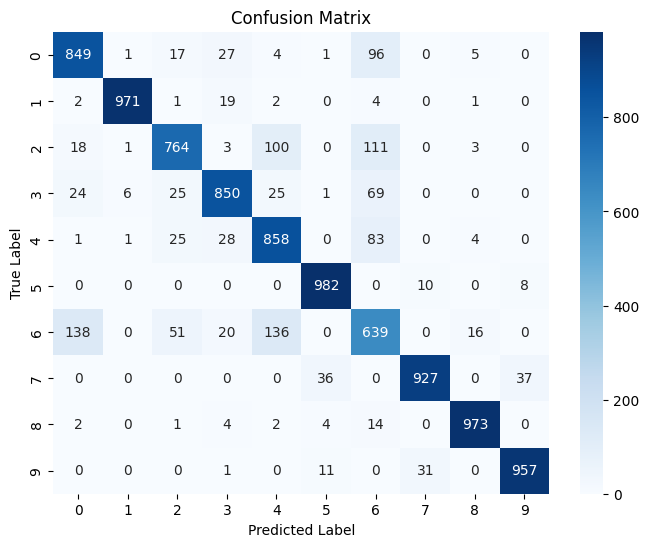

In [ ]:
# compute the confusion matrix
cm = confusion_matrix(y_test, y_pred)
# set the figure size
plt.figure(figsize=(8, 6))

# plot the confusion matrix as a heatmap
sns.heatmap(cm, annot=True, fmt='d', cmap='Blues')

#add labels and title
plt.xlabel("Predicted Label")
plt.ylabel("True Label")
plt.title("Confusion Matrix")

#show the plot
plt.show()



Explaination:

In this part, a confusion matrix is also computed and shown as a heatmap.The rows show the true classes and the columns show the predicted classes.This plot clearly visualize the relationship between true labels and predicted labels,which helps clearly see which classes are classified correctly and which classes are often confused.

In conclusion,the model performs similarly on all datasets by comparing all results.In the trainiing process,the training  curve remain close to the validation curve, and the validation loss did not significantly increase. This showes that the model does not show clear signs of overfitting and has great generalilzation ability.

Based on these conclusions,the model is well-fitted. It can learn useful features from the training data and achieve good performance on the test set.


**6.Visualize result**

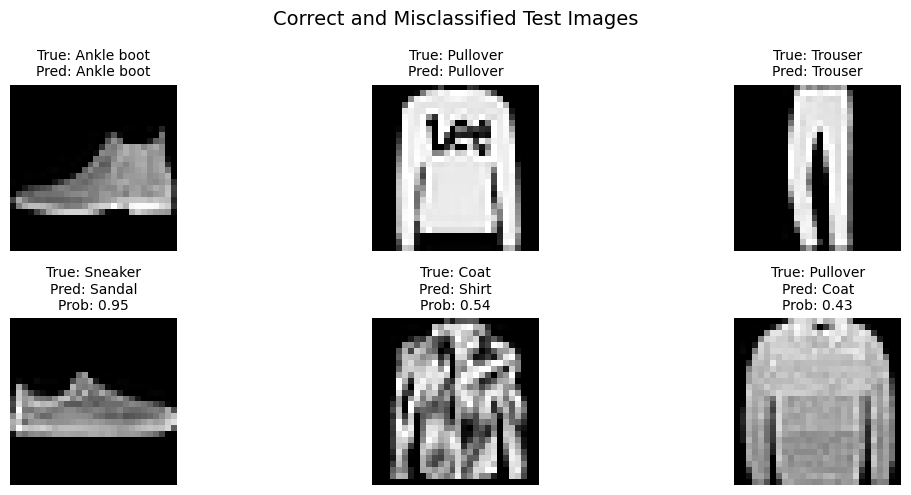

In [ ]:
#define the name of categories
class_names = [
    'T-shirt/top', 'Trouser', 'Pullover', 'Dress', 'Coat',
    'Sandal', 'Shirt', 'Sneaker', 'Bag', 'Ankle boot'
]

# predict the corrcect index
correct_idx = np.where(y_pred == y_test)[0][:3]

#predict the wrong index
incorrect_idx = np.where(y_pred != y_test)[0][:3]

# create plot
plt.figure(figsize=(12, 5))

# correct predict
for i, idx in enumerate(correct_idx):
    plt.subplot(2, 3, i + 1)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title(
        f"True: {class_names[np.argmax(y_test_cat[idx])]}\n"
        f"Pred: {class_names[y_pred[idx]]}",
        fontsize=10
    )
    plt.axis('off')

# wrong predict
for i, idx in enumerate(incorrect_idx):
    prob = np.max(y_prob[idx])
    plt.subplot(2, 3, i + 4)
    plt.imshow(X_test[idx].reshape(28, 28), cmap='gray')
    plt.title(
        f"True: {class_names[y_test[idx]]}\n"
        f"Pred: {class_names[y_pred[idx]]}\n"
        f"Prob: {prob:.2f}",
        fontsize=10
    )
    plt.axis('off')

plt.suptitle("Correct and Misclassified Test Images", fontsize=14)
plt.tight_layout()
plt.show()

Explaination:

In this part, six images are visualized,including three correct classified prediction and three wrong classified prediction with their probabilities. Foe each image,it contain their true label and the predicted label.This step help us easy to see which images is handles well and which image is hard to handle with.Based on the results,we can see some misclassifies is often happen because sneaker is smiliar to sandal,pullover is similiar to coat and somtimes it because of the image is noisy and some patterns are unusual.

In summary,the model performs great.This correct predictions show that it can learn important features and generalize to new data.At the same time,the wrong predictions also show it still got some troubles.